In [3]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits


pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 100)

FITS_PATH = next(
    Path("../temp").glob("2025W37_1A_0290_1*.fits")
)

print(f"File: {FITS_PATH.name}")
print(f"Size: {FITS_PATH.stat().st_size:,} bytes")

File: 2025W37_1A_0290_1_30be63a28420.fits
Size: 65,413,440 bytes


In [2]:
hdul = fits.open(FITS_PATH)

print(f"Total HDU: {len(hdul)}")

Total HDU: 7


In [3]:
overview = []

for index, hdu in enumerate(hdul):
    data = hdu.data

    overview.append({
        "Index": index,
        "HDU Name": hdu.name,
        "Type": type(hdu).__name__,
        "Shape": getattr(data, "shape", None),
        "Data Type": getattr(data, "dtype", None),
        "Header Cards": len(hdu.header),
    })

overview_df = pd.DataFrame(overview)

display(overview_df)

,Index,HDU Name,Type,Shape,Data Type,Header Cards
0,0,PRIMARY,PrimaryHDU,None,None,5
1,1,IMAGE,ImageHDU,"(2040, 2040)",>f4,293
2,2,FLAGS,CompImageHDU,"(2040, 2040)",int32,185
3,3,VARIANCE,ImageHDU,"(2040, 2040)",>f4,119
4,4,ZODI,ImageHDU,"(2040, 2040)",>f4,122
5,5,EPSF,BinTableHDU,"(441,)","(numpy.record, [('BINX', '>i4'), ('BINY', '>i4'), ('XCENTER', '>f4'), ('YCENTER', '>f4'), ('XWID...",56
6,6,WCS-WAVE,BinTableHDU,"(1,)","(numpy.record, [('X', '>i4', (9,)), ('Y', '>i4', (9,)), ('VALUES', '>f4', (9, 9, 2))])",22


In [5]:
def inspect_header(hdu):
    header_data = []

    for card in hdu.header.cards:
        header_data.append({
            "Keyword": card.keyword,
            "Value": str(card.value),
            "Comment": card.comment,
        })

    return pd.DataFrame(header_data)

In [7]:
def inspect_table(hdu):
    columns = []

    for column in hdu.columns:
        columns.append({
            "Name": column.name,
            "Format": column.format,
            "Unit": column.unit,
            "Dimension": column.dim,
        })

    return pd.DataFrame(columns)

IMAGE HDU Visualization

In [9]:
with fits.open(FITS_PATH) as hdul:
    image_data = hdul["IMAGE"].data.astype(np.float32).copy()

In [10]:
image_stats = {
    "Shape": image_data.shape,
    "Data Type": image_data.dtype,
    "Minimum": np.nanmin(image_data),
    "Maximum": np.nanmax(image_data),
    "Mean": np.nanmean(image_data),
    "Median": np.nanmedian(image_data),
    "Standard Deviation": np.nanstd(image_data),
    "NaN Count": np.isnan(image_data).sum(),
    "Infinite Count": np.isinf(image_data).sum(),
}

display(
    pd.DataFrame(
        image_stats.items(),
        columns=["Property", "Value"]
    )
)

,Property,Value
0,Shape,"(2040, 2040)"
1,Data Type,float32
2,Minimum,-5579.410645
3,Maximum,2730.609619
4,Mean,0.865649
5,Median,0.523553
6,Standard Deviation,9.37666
7,NaN Count,163
8,Infinite Count,0


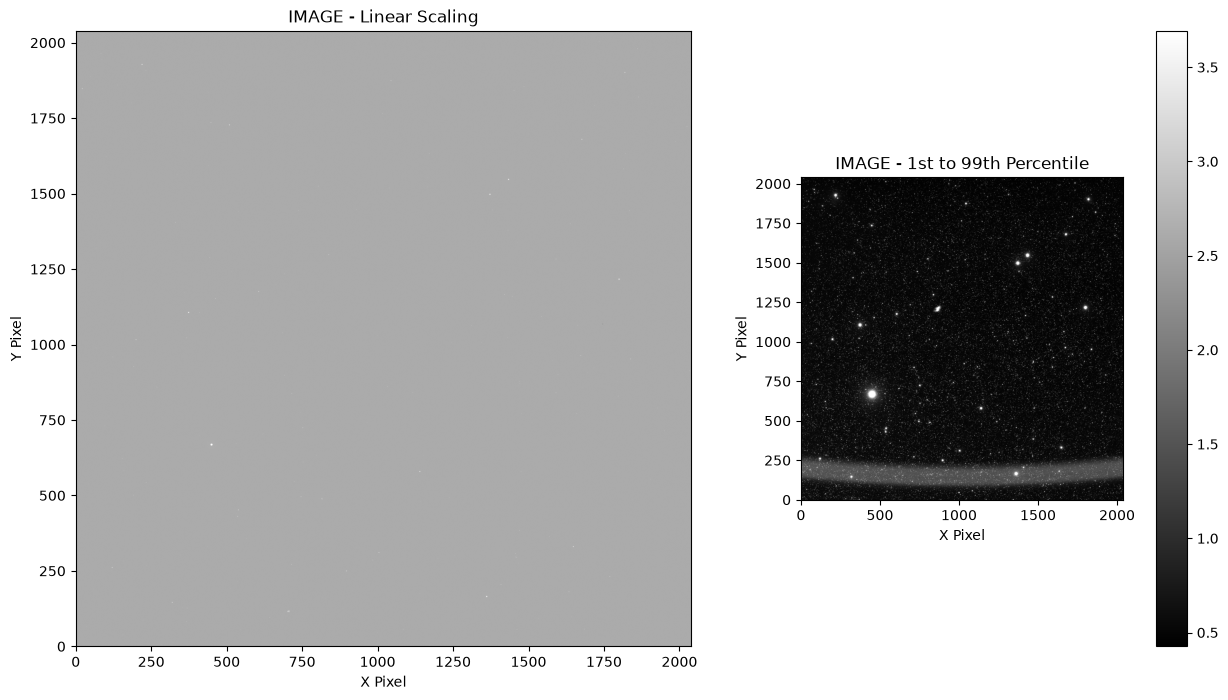

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

# Linear scaling
im1 = axes[0].imshow(
    image_data,
    origin="lower",
    cmap="gray"
)

axes[0].set_title("IMAGE - Linear Scaling")
axes[0].set_xlabel("X Pixel")
axes[0].set_ylabel("Y Pixel")

# Percentile scaling
vmin, vmax = np.nanpercentile(
    image_data,
    [1, 99]
)

im2 = axes[1].imshow(
    image_data,
    origin="lower",
    cmap="gray",
    vmin=vmin,
    vmax=vmax
)

axes[1].set_title("IMAGE - 1st to 99th Percentile")
axes[1].set_xlabel("X Pixel")
axes[1].set_ylabel("Y Pixel")

fig.colorbar(im2, ax=axes[1], fraction=0.46)

plt.tight_layout()
plt.show()

Pixel Value Distribution


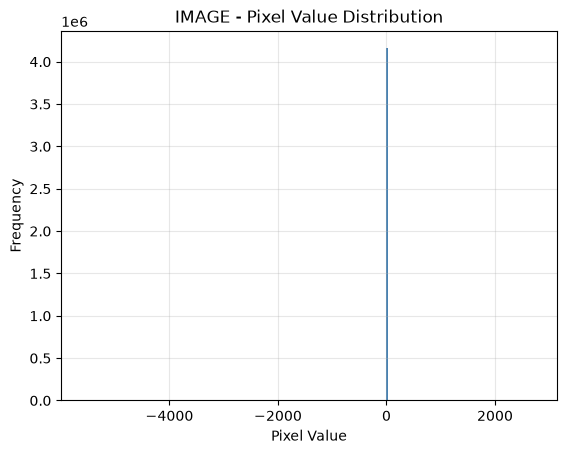

In [13]:
plt.hist(
    image_data[np.isfinite(image_data)].ravel(),
    bins=200,
    color="steelblue"
)

plt.title("IMAGE - Pixel Value Distribution")
plt.xlabel("Pixel Value")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)

plt.show()

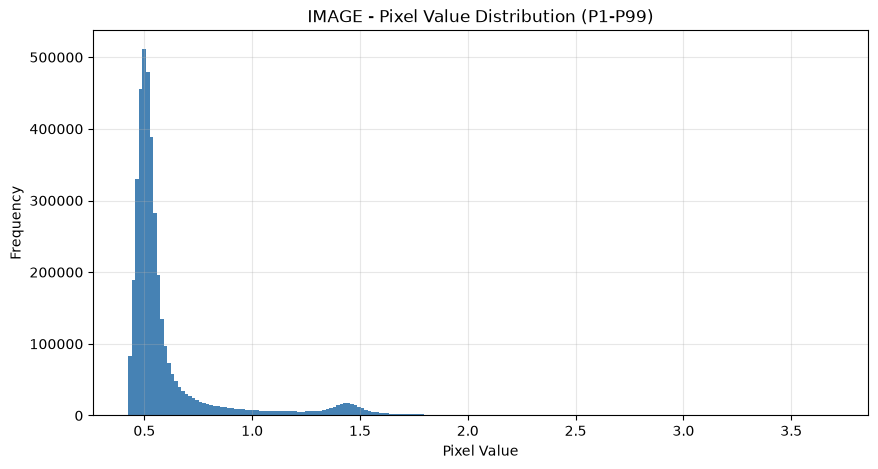

In [15]:
p1, p99 = np.nanpercentile(
    image_data[np.isfinite(image_data)],
    [1, 99]
)

plt.figure(figsize=(10, 5))

plt.hist(
    image_data[np.isfinite(image_data)].ravel(),
    bins=200,
    range=(p1, p99),
    color="steelblue"
)

plt.title("IMAGE - Pixel Value Distribution (P1-P99)")
plt.xlabel("Pixel Value")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)

plt.show()


In [4]:
rows = []
for hdu_name in ["PRIMARY", "IMAGE"]:
    header = hdul[hdu_name].header

    for key in header:
        if key in ["COMMENT", "HISTORY"]:
            continue

        rows.append({
            "HDU": hdu_name,
            "Keyword": key,
            "Value": str(header[key]),
            "Comment": header.comments[key],
        })

display(pd.DataFrame(rows))

NameError: name 'hdul' is not defined